In [1]:
%matplotlib inline

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import stft, resample_poly
from ipywidgets import VBox, HBox, FloatSlider, Output, Label, Dropdown
from IPython.display import display, clear_output, Audio

In [2]:
def db_scale(x, amin=1e-10):
    return 20.0 * np.log10(np.maximum(x, amin))

def compute_spectrogram(x, sr, nfft=2048, hop=512):
    noverlap = nfft - hop
    f, t, Z = stft(
        x,
        fs=sr,
        window="hann",
        nperseg=nfft,
        noverlap=noverlap,
        nfft=nfft,
        boundary=None,
        padded=False
    )
    S_mag = np.abs(Z)
    S_db = db_scale(S_mag)
    return f, t, S_db

def plot_spec(ax, f, t, S_db, title, fmin, fmax, vmin=-80, vmax=None, log_freq=False):
    # Convert frequency to kHz for display
    y = f / 1000.0
    mesh = ax.pcolormesh(t, y, S_db, shading="auto", cmap="magma", vmin=vmin, vmax=vmax)
    ax.set_ylabel("Frequency (kHz)")
    ax.set_xlabel("Time (s)")
    ax.set_title(title)
    if log_freq:
        ax.set_yscale("log")
        ax.set_ylim(fmin / 1000, fmax / 1000)
    cbar = plt.colorbar(mesh, ax=ax, format="%.0f dB")
    cbar.set_label("Magnitude (dB)")

def plot_time(ax, x, sr):
    ax.set_ylabel("")
    ax.set_xlabel("Amp")
    t = np.array([i/sr for i in range(len(x))])
    ax.plot(t, x)

def plot_freq(ax, x, sr, fmin, fmax):
    N = len(x)
    f = np.fft.rfftfreq(N, 1/sr)
    X = np.fft.rfft(x)
    mag = np.abs(X) / N
    ax.plot(f, mag)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Amplitude (linear)')
    ax.set_xlim(fmin, fmax)
    ax.set_title('One-sided amplitude spectrum')
    ax.grid(True, alpha=0.3)


def make_envelope(x, sr, max_points=4000):
    """Downsample x into min/max envelope for fast plotting."""
    n = len(x)
    if n == 0:
        return np.array([0.0]), np.array([0.0]), np.array([0.0])
    if n <= max_points:
        t = np.arange(n) / sr
        return t, x, x
    hop = int(np.ceil(n / max_points))
    idx = np.arange(0, n, hop)
    # Use ufunc.reduceat for fast min/max per chunk
    y_min = np.minimum.reduceat(x, idx)
    y_max = np.maximum.reduceat(x, idx)
    t = idx / sr
    return t, y_min, y_max

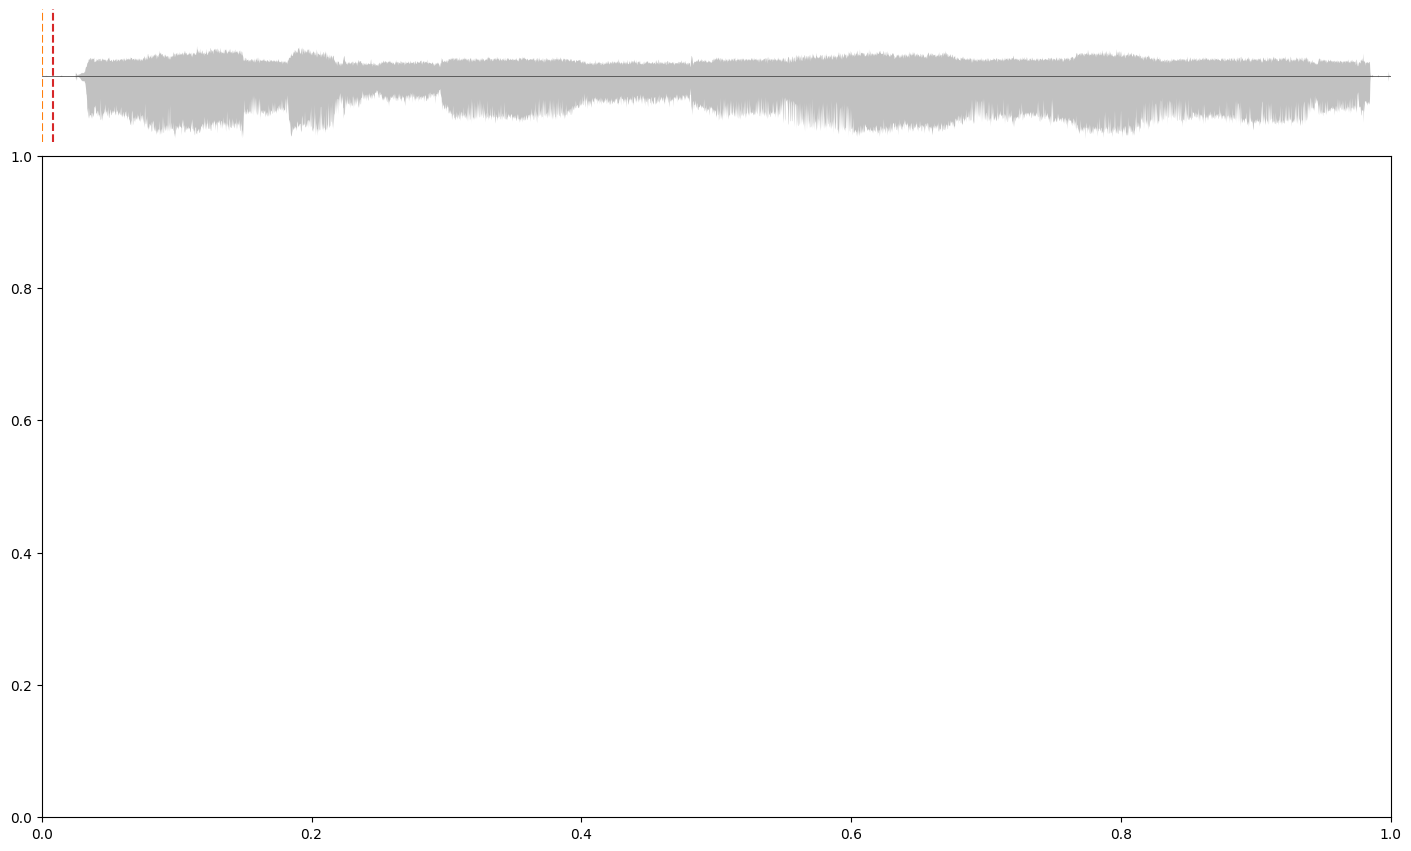

In [ ]:
# --------- Configuration (edit these) ---------
# audio_path = "../samples/freesound_community-uas-drone-pass-04-71065.mp3"
audio_path = "../samples/klemenflerin-drone-fly-397287.mp3"
# audio_path = "../samples/u_fdacz9w8dw-drone-fly-amp-crash-200744.mp3"
# audio_path = "../samples/ya_dmutro-military-fpv-drone-attack-with-impact-explosion-439286.mp3"
target_sr = None                  # e.g., 16000 to resample, or None to keep original
channel = 0                  # "mono" to mix, or an integer channel index (0-based)
log_freq = False
vmin_db = -80.0
vmax_db = 0.0
fig_width = 14
dpi = 80
minimap_points = 4000
# ----------------------------------------------

def resample_if_needed(data, sr_in, sr_target):
    if sr_target is None or sr_target <= 0 or sr_target == sr_in:
        return data, sr_in
    g = np.gcd(sr_in, sr_target)
    up = sr_target // g
    down = sr_in // g
    res = np.vstack([resample_poly(ch, up, down) for ch in data.T]).T
    return res, sr_target

# Load audio once
data, sr = sf.read(audio_path, always_2d=True)
if data.size == 0:
    raise RuntimeError("Empty or unsupported audio file.")
data, sr = resample_if_needed(data, sr, target_sr if target_sr else None)

total_duration = len(data) / sr
num_channels = data.shape[1]

x_full = data[:, channel]
t_env, y_min_env, y_max_env = make_envelope(x_full, sr, max_points=minimap_points)
y_abs_max = max(1e-9, float(np.max(np.abs([y_min_env, y_max_env]))))

w_analysis = Dropdown(options=["time", "freq", "spec"], value="spec", description="Type:")
w_NFFT = Dropdown(options=[2**i for i in range(6, 14)], value=1024, description="NFFT:")
w_OFFT = Dropdown(options=[2**i for i in range(1, 6)], value=4, description="OFFT:")

w_start = FloatSlider(
    value=0.0, min=0.0, max=max(0.0, total_duration - 0.01),
    step=max(0.001, total_duration / 1000.0),
    description="Start (s)", continuous_update=True, readout_format=".2f"
)

drange = min(5, total_duration)
w_dur = FloatSlider(
    value=float(min(2.0, total_duration)), min=0.01, max=max(0.01, drange),
    step=max(0.001, drange / 1000.0),
    description="Duration (s)", continuous_update=True, readout_format=".2f"
)

w_fstart = FloatSlider(
    value=0.0, min=0.0, max=sr/2,
    step=max(0.001, 1),
    description="Fstart", continuous_update=True, readout_format=".2f"
)
w_fwidth = FloatSlider(
    value=sr/2, min=1, max=sr/2,
    step=max(0.001, 1),
    description="Fwidth", continuous_update=True, readout_format=".2f"
)

w_analysis.layout.width = "150px"
w_NFFT.layout.width = "150px"
w_OFFT.layout.width = "150px"
w_dur.layout.width = f"{fig_width * dpi * 1.15 - 450}px"
w_start.layout.width = f"{fig_width * dpi * 1.15}px"

w_fstart.layout.width = f"{fig_width * dpi * 0.55}px"
w_fwidth.layout.width = f"{fig_width * dpi * 0.55}px"


out = Output()

def update_plot(change):
    start = max(0.0, min(w_start.value, total_duration))
    dur = max(0.01, min(w_dur.value, total_duration - start))
    end = start + dur
    end = min(end, total_duration)
    start = end - dur

    s_idx = int(round(start * sr))
    e_idx = int(round(end * sr))
    s_idx = max(0, min(s_idx, len(data)-1))
    e_idx = max(s_idx + 1, min(e_idx, len(data)))

    x = data[s_idx:e_idx, channel]

    fmin = w_fstart.value
    fmax = fmin + w_fwidth.value
    fmax = min(fmax, sr/2)
    fmin = fmax - w_fwidth.value

    with out:
        clear_output(wait=True)
        # Figure with minimap on top and spectrogram below
        fig, (ax_top, ax_plot) = plt.subplots(
            2, 1, figsize=(fig_width, fig_width * 0.6),
            gridspec_kw={"height_ratios": [1, 5]},
            constrained_layout=True
        )

        # Minimap: fast downsampled envelope + start/end lines
        ax_top.fill_between(t_env, y_min_env, y_max_env, color="0.6", alpha=0.6, linewidth=0)
        ax_top.plot([0, total_duration], [0, 0], color="0.2", linewidth=0.5)  # zero line
        ax_top.axvline(start, color="C1", linestyle="--", linewidth=1.5)
        ax_top.axvline(end, color="C3", linestyle="--", linewidth=1.5)
        ax_top.set_xlim(0, total_duration)
        ax_top.set_ylim(-1.05 * y_abs_max, 1.05 * y_abs_max)
        ax_top.set_axis_off()

        # Spectrogram for selected segment
        title = f"Spectrogram ({channel}) — {start:.2f}s to {end:.2f}s — sr={sr} Hz"

        if w_analysis.value == "spec":
            nfft = w_NFFT.value
            overlap = w_OFFT.value
            while nfft > len(x):
                nfft //= 2
            overlap = min(overlap, nfft)
            f, t, S_db = compute_spectrogram(x, sr, nfft=nfft, hop=nfft//overlap)
            plot_spec(ax_plot, f, t, S_db, title, fmin, fmax, vmin=vmin_db, vmax=vmax_db, log_freq=log_freq)
        elif w_analysis.value == "freq":
            plot_freq(ax_plot, x, sr, fmin, fmax)
        else:
            plot_time(ax_plot, x, sr)

        plt.show()
        display(Audio(x, rate=sr))

# Hook up events and render once
for w in (w_analysis, w_NFFT, w_OFFT, w_start, w_dur, w_fwidth, w_fstart):
    w.observe(update_plot, names="value")

display(VBox([
    Label(f"Loaded: {audio_path} — channels: {num_channels}, sr: {sr} Hz, duration: {total_duration:.2f} s"),
    HBox([w_analysis, w_NFFT, w_OFFT, w_dur]),
    HBox([w_fstart, w_fwidth]),
    w_start,
    out
]))

update_plot(None)